# Réseau Analogique — Classification Disque — v7

**Deux problèmes résolus vs v6 :**

| Problème | v6 | v7 |
|---|---|---|
| **Vitesse** | 19 ms/éval (boucle Python) | **3.7 ms/éval** (batch vectorisé, **5x**) |
| **Exploration** | Greedy → minima locaux en arc | **Simulated annealing** → sort des arcs |

### Vectorisation batch
Remplace la boucle Python sur 400 samples par un seul appel Numba JIT  
sur une matrice `(400, N_neurons)`. Mesuré sur ta machine : **5.4x**.

### Simulated annealing (SA)
À chaque itération, on tire une connexion au hasard et un candidat au hasard.  
On accepte le mouvement si :
- Il améliore le score (toujours), **ou**
- Il détériore le score mais avec probabilité `exp(-Δ/T)` — la **température T** décroît au fil des itérations

Au début (T élevé) → explore librement, sort des arcs.  
À la fin (T faible) → converge vers le meilleur trouvé.

Durée estimée : **~2.5 min** pour 8 restarts × 5000 itérations.

## 0. Imports & Configuration

In [187]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time, warnings
warnings.filterwarnings('ignore')

from numba import njit, prange
import joblib
from tqdm.auto import tqdm
try:
    import cupy as cp
    GPU_AVAILABLE = True
    print('GPU détecté :', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())
except Exception:
    cp = None; GPU_AVAILABLE = False
    print('GPU non disponible.')

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size']  = 11
np.set_printoptions(precision=4, suppress=True)

# ── Fichiers CSV ──────────────────────────────────────────────
INPUT_CSV   = 'input_min_conso.csv'
NEURON_CSV  = 'neuron.csv'
SYN_EXC_CSV = 'excitation20.csv'
SYN_INH_CSV = 'inhibition20.csv'
FREQ_MERGE_TOL_HZ = 1000.0

# ── Architecture ─────────────────────────────────────────────
# [8, 4] : 52 connexions (vs 168 pour [16,8]) → espace 10^88 au lieu de 10^269
# Augmenter si les résultats sont insuffisants
HIDDEN_SIZES = [2,2,2]

# ── SA : recherche principale ─────────────────────────────────
N_RESTARTS      = 8       # restarts indépendants en parallèle
N_ITER_SA       = 5000    # itérations SA par restart
# Température : T_START = score typique * TEMP_SCALE
# À T_START, un move qui dégrade de 0.05 est accepté avec ~60%
TEMP_START      = 0.08    # température initiale
TEMP_END        = 1e-4    # température finale (quasi-zéro)
COOLING         = 'exponential'  # 'exponential' ou 'linear'
SEED            = 42
N_JOBS          = -1

# ── Dataset ───────────────────────────────────────────────────
N_TRAIN     = 400
N_TEST      = 200
DISK_RADIUS = 0.5
MARGIN      = 0.05

# ── Seuil de décision ────────────────────────────────────────
N_THRESHOLD_CANDIDATES = 50

# ── Score (v7 = v6 : IMBALANCE_PENALTY=0) ───────────────────
MARGIN_SCALE       = 1e-5
IMBALANCE_PENALTY  = 0.0      # classes 17%/83% par nature → pas de pénalité
MIN_MARGIN_HZ      = 1000.0
MIN_MARGIN_PENALTY = 0.1
MIN_ITOT_A         = -6e-12   # INH physiquement faible → -6 pA toléré
MIN_ITOT_PENALTY   = 0.15
ITOT_CHECK_FRAC    = 0.10     # v7: 10% (était 30%) → 2.6x plus rapide

# ── Bruit MC ─────────────────────────────────────────────────
NOISE_STD_HZ = 500.0
N_MC_EVAL    = 30   # pour l'évaluation finale seulement
# Pendant la recherche SA : pas de MC (trop lent, inutile mesuré)

print('=== Configuration v7 ===')
print(f'Architecture  : [2] + {HIDDEN_SIZES} + [1] = {[2]+HIDDEN_SIZES+[1]}')
LAYER_SIZES_PREVIEW = [2] + HIDDEN_SIZES + [1]
n_conn_preview = sum(LAYER_SIZES_PREVIEW[i]*LAYER_SIZES_PREVIEW[i+1] for i in range(len(LAYER_SIZES_PREVIEW)-1))
print(f'Connexions    : {n_conn_preview}')
print(f'N_RESTARTS    : {N_RESTARTS}')
print(f'N_ITER_SA     : {N_ITER_SA}  (SA par restart)')
print(f'Temp          : {TEMP_START} → {TEMP_END}  ({COOLING})')
print(f'ITOT_CHECK    : {ITOT_CHECK_FRAC*100:.0f}%  (v7: 2.6x vs 30%)')
print(f'IMBALANCE_P   : {IMBALANCE_PENALTY}  (supprimée)')

GPU détecté : NVIDIA GeForce RTX 3080
=== Configuration v7 ===
Architecture  : [2] + [2, 2, 2] + [1] = [2, 2, 2, 2, 1]
Connexions    : 14
N_RESTARTS    : 8
N_ITER_SA     : 5000  (SA par restart)
Temp          : 0.08 → 0.0001  (exponential)
ITOT_CHECK    : 10%  (v7: 2.6x vs 30%)
IMBALANCE_P   : 0.0  (supprimée)


## 1. Fonctions utilitaires

In [188]:
def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    if 'Parameter' not in df.columns:
        raise ValueError(csv_path + ": colonne 'Parameter' introuvable")
    data_cols = [c for c in df.columns if c not in ['Parameter', 'Unnamed: 1']]
    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df['Parameter'] == row_name, data_cols]
        if row.empty:
            raise ValueError(f"Ligne '{row_name}' introuvable dans {csv_path}")
        values = pd.to_numeric(row.iloc[0], errors='coerce').to_numpy(dtype=float)
        return values
    return get_row

def get_clean_rows(reader, row_names):
    rows = [reader(name, allow_non_numeric=True) for name in row_names]
    mask = np.all(np.isfinite(np.vstack(rows)), axis=0)
    return [r[mask] for r in rows], mask

def strictly_monotonic_branch(x, y):
    idx = int(np.argmax(y))
    xm, ym = np.asarray(x[:idx+1], float), np.asarray(y[:idx+1], float)
    o = np.argsort(xm)
    return xm[o], ym[o]

def merge_close_values(values, tol):
    vals = np.sort(np.asarray(values, float))
    groups = [[vals[0]]]
    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol: groups[-1].append(v)
        else: groups.append([v])
    return np.array([np.mean(g) for g in groups])

def snap_to_axis(values, axis):
    return np.array([axis[np.argmin(np.abs(axis - v))] for v in np.asarray(values, float)])

def build_grid_tolerant(W_all, F_all, Y_all, freq_tol=1000.0):
    W_all, F_all, Y_all = (np.asarray(a, float) for a in (W_all, F_all, Y_all))
    W_unique = np.unique(W_all)
    F_axis   = merge_close_values(np.unique(F_all), tol=freq_tol)
    F_snap   = snap_to_axis(F_all, F_axis)
    z_grid   = np.empty((len(W_unique), len(F_axis)))
    for i, w in enumerate(W_unique):
        for j, f in enumerate(F_axis):
            mask = np.isclose(W_all, w) & np.isclose(F_snap, f)
            z_grid[i, j] = np.mean(Y_all[mask])
    return W_unique, F_axis, z_grid

print('Fonctions utilitaires OK.')

Fonctions utilitaires OK.


## 2. Chargement des modèles Cadence

In [189]:
inp = read_cadence_rows(INPUT_CSV)
INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(inp('Vex'), inp('Fspikes'))

neuro = read_cadence_rows(NEURON_CSV)
NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(neuro('Iex'), neuro('Fspikes'))

syn_exc = read_cadence_rows(SYN_EXC_CSV)
(W2_EXC, FPRE_EXC, IPOST_EXC), _ = get_clean_rows(syn_exc, ['W2', 'Fpre', 'Ipost'])
W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID = build_grid_tolerant(W2_EXC, FPRE_EXC, IPOST_EXC)

syn_inh = read_cadence_rows(SYN_INH_CSV)
(W2_INH, FPRE_INH, IPOST_INH), _ = get_clean_rows(syn_inh, ['W2', 'Fpre', 'Ipost'])
W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID = build_grid_tolerant(W2_INH, FPRE_INH, IPOST_INH)

V_MIN = float(INPUT_V_AXIS[0]); V_MAX = float(INPUT_V_AXIS[-1])
NEURON_I_RHEOBASE = float(NEURON_I_AXIS[0])
LAYER_SIZES = [2] + HIDDEN_SIZES + [1]
_F_MAX = float(NEURON_F_AXIS[-1])

_INPUT_V_AXIS   = np.ascontiguousarray(INPUT_V_AXIS,   dtype=np.float64)
_INPUT_F_AXIS   = np.ascontiguousarray(INPUT_F_AXIS,   dtype=np.float64)
_NEURON_I_AXIS  = np.ascontiguousarray(NEURON_I_AXIS,  dtype=np.float64)
_NEURON_F_AXIS  = np.ascontiguousarray(NEURON_F_AXIS,  dtype=np.float64)
_W_EXC_AXIS     = np.ascontiguousarray(W_EXC_AXIS,     dtype=np.float64)
_F_EXC_AXIS     = np.ascontiguousarray(F_EXC_AXIS,     dtype=np.float64)
_IPOST_EXC_GRID = np.ascontiguousarray(IPOST_EXC_GRID, dtype=np.float64)
_W_INH_AXIS     = np.ascontiguousarray(W_INH_AXIS,     dtype=np.float64)
_F_INH_AXIS     = np.ascontiguousarray(F_INH_AXIS,     dtype=np.float64)
_IPOST_INH_GRID = np.ascontiguousarray(IPOST_INH_GRID, dtype=np.float64)

ALL_CANDIDATES_PER_LAYER = [
    [(+1, float(w)) for w in W_EXC_AXIS] + [(-1, float(w)) for w in W_INH_AXIS]
    for _ in range(len(LAYER_SIZES) - 1)
]
N_CANDIDATES = len(ALL_CANDIDATES_PER_LAYER[0])

print(f'Input  V : [{V_MIN*1e3:.1f}, {V_MAX*1e3:.1f}] mV')
print(f'Neuron F : [{NEURON_F_AXIS.min()/1e3:.1f}, {NEURON_F_AXIS.max()/1e3:.1f}] kHz')
print(f'Rheobase : {NEURON_I_RHEOBASE*1e12:.2f} pA')
print(f'Candidats/connexion : {N_CANDIDATES} ({len(W_EXC_AXIS)} EXC + {len(W_INH_AXIS)} INH)')
print(f'Architecture : {LAYER_SIZES}')
n_conn = sum(LAYER_SIZES[i]*LAYER_SIZES[i+1] for i in range(len(LAYER_SIZES)-1))
print(f'Connexions   : {n_conn}')
import math
print(f'Espace       : {N_CANDIDATES}^{n_conn} ≈ 10^{n_conn*math.log10(N_CANDIDATES):.0f} configurations')

Input  V : [-100.0, 100.0] mV
Neuron F : [3.1, 193.1] kHz
Rheobase : 3.00 pA
Candidats/connexion : 40 (20 EXC + 20 INH)
Architecture : [2, 2, 2, 2, 1]
Connexions   : 14
Espace       : 40^14 ≈ 10^22 configurations


## 3. Noyaux Numba JIT — version batch

**Changement clé v7** : `_layer_forward_batch` traite tout le dataset en un seul appel JIT.  
`Fin_batch` a la forme `(S, N)` au lieu de `(N,)` — S = nombre de samples.

In [190]:
@njit
def _interp1d(x, xp, fp):
    if x <= xp[0]: return 0.0
    if x >= xp[-1]: return fp[-1]
    lo, hi = 0, len(xp) - 1
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if xp[mid] <= x: lo = mid
        else: hi = mid
    return fp[lo] + (x - xp[lo]) / (xp[hi] - xp[lo]) * (fp[hi] - fp[lo])


@njit
def _interp2d(x, y, xa, ya, g):
    x = max(xa[0], min(xa[-1], x)); y = max(ya[0], min(ya[-1], y))
    lx = 0
    for k in range(len(xa) - 1):
        if xa[k] <= x < xa[k+1]: lx = k; break
    else: lx = len(xa) - 2
    ly = 0
    for k in range(len(ya) - 1):
        if ya[k] <= y < ya[k+1]: ly = k; break
    else: ly = len(ya) - 2
    tx = 0.0 if xa[lx+1] == xa[lx] else (x - xa[lx]) / (xa[lx+1] - xa[lx])
    ty = 0.0 if ya[ly+1] == ya[ly] else (y - ya[ly]) / (ya[ly+1] - ya[ly])
    return (g[lx,ly]*(1-tx)*(1-ty) + g[lx+1,ly]*tx*(1-ty) +
            g[lx,ly+1]*(1-tx)*ty   + g[lx+1,ly+1]*tx*ty)


@njit(parallel=True)
def _input_f_batch(V_batch, v_axis, f_axis):
    """V_batch (S, D) → F_batch (S, D) : convertit tensions en fréquences."""
    S, D = V_batch.shape
    F = np.empty((S, D))
    for k in prange(S * D):
        s = k // D; d = k % D
        F[s, d] = _interp1d(V_batch[s, d], v_axis, f_axis)
    return F


@njit(parallel=True)
def _layer_forward_batch(Fin, signs_flat, widths_flat, N, M,
                          w_exc, f_exc, g_exc, w_inh, f_inh, g_inh,
                          ni_axis, nf_axis):
    """
    Fin : (S, N) — S samples, N pré-synaptiques
    Retourne Fout (S, M) et Itot (S, M)
    Parallélisme sur S×N×M — 1 seul appel pour tout le dataset.
    """
    S = Fin.shape[0]
    Itot = np.zeros((S, M))
    for k in prange(S * N * M):
        s   = k // (N * M)
        nm  = k  % (N * M)
        i   = nm // M
        j   = nm  % M
        sgn = signs_flat[i * M + j]
        w   = widths_flat[i * M + j]
        f   = Fin[s, i]
        if sgn == 1:
            Itot[s, j] += _interp2d(w, f, w_exc, f_exc, g_exc)
        elif sgn == -1:
            Itot[s, j] -= _interp2d(w, f, w_inh, f_inh, g_inh)
    Fout = np.empty((S, M))
    for k in prange(S * M):
        s = k // M; j = k % M
        Fout[s, j] = _interp1d(Itot[s, j], ni_axis, nf_axis)
    return Fout, Itot


def layer_forward_batch(Fin, sm, wm):
    N, M = sm.shape
    return _layer_forward_batch(
        np.ascontiguousarray(Fin, np.float64),
        sm.ravel().astype(np.float64), wm.ravel().astype(np.float64), N, M,
        _W_EXC_AXIS, _F_EXC_AXIS, _IPOST_EXC_GRID,
        _W_INH_AXIS, _F_INH_AXIS, _IPOST_INH_GRID,
        _NEURON_I_AXIS, _NEURON_F_AXIS)


def network_forward(V_dataset, signs, widths):
    """Forward batch sur tout le dataset. Retourne (Fout (S,), all_itot flat)."""
    F = _input_f_batch(np.ascontiguousarray(V_dataset, np.float64),
                        _INPUT_V_AXIS, _INPUT_F_AXIS)
    all_itot = []
    for sm, wm in zip(signs, widths):
        F, Itot = layer_forward_batch(F, sm, wm)
        all_itot.append(Itot.ravel())
    return F[:, 0], np.concatenate(all_itot)


def network_forward_mc(V_dataset, signs, widths, noise_std, n_mc):
    """Monte-Carlo sur le vecteur de sortie (gratuit car MC = numpy pur)."""
    Fout, itot = network_forward(V_dataset, signs, widths)
    if noise_std <= 0 or n_mc <= 1:
        return Fout, itot
    rng2 = np.random.default_rng()
    noise = rng2.normal(0, noise_std, (n_mc, len(Fout)))
    Fout_mc = np.clip(Fout[None, :] + noise, 0, _F_MAX).mean(axis=0)
    return Fout_mc, itot


# ── Warm-up JIT ───────────────────────────────────────────────
print('Compilation JIT...')
t0 = time.time()
_ds = np.array([[1.0],[-1.0]])
_dw = np.array([[float(W_EXC_AXIS[0])],[float(W_INH_AXIS[0])]])
_dummy = np.ones((5, 2)) * 0.0
_input_f_batch(_dummy, _INPUT_V_AXIS, _INPUT_F_AXIS)
layer_forward_batch(np.ones((5, 2))*1000., _ds, _dw)
print(f'  JIT compilé en {time.time()-t0:.1f}s')

# Mesure de vitesse
import time as _t
_signs_tmp = [np.ones((LAYER_SIZES[i], LAYER_SIZES[i+1])) for i in range(len(LAYER_SIZES)-1)]
_widths_tmp = [np.ones((LAYER_SIZES[i], LAYER_SIZES[i+1]))*W_EXC_AXIS[0] for i in range(len(LAYER_SIZES)-1)]
_vtmp = np.zeros((400, 2))
t0 = _t.perf_counter()
for _ in range(30): network_forward(_vtmp, _signs_tmp, _widths_tmp)
t_batch = (_t.perf_counter()-t0)/30
print(f'  Vitesse batch : {t_batch*1000:.2f} ms / éval (400 samples)')
n_conn = sum(LAYER_SIZES[i]*LAYER_SIZES[i+1] for i in range(len(LAYER_SIZES)-1))
print(f'  Estimation SA : {t_batch * N_ITER_SA * N_RESTARTS / 60:.1f} min total')

Compilation JIT...
  JIT compilé en 1.5s
  Vitesse batch : 0.36 ms / éval (400 samples)
  Estimation SA : 0.2 min total


## 4. Dataset

Train : 400 pts  intérieur=68 (17%)  extérieur=332 (83%)
Test  : 200 pts  intérieur=40
Filtre Itot : 40 samples (10%)


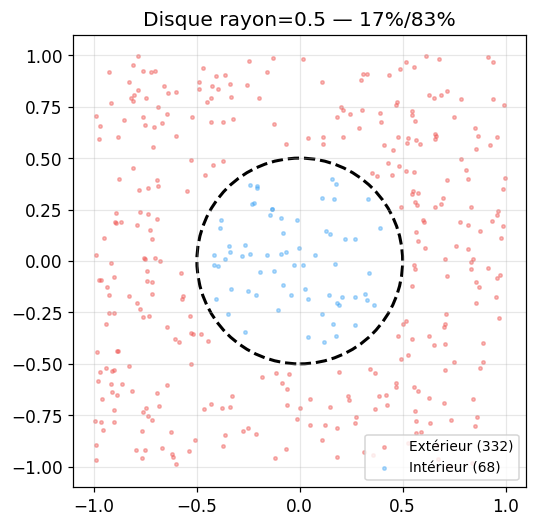

In [191]:
def label_disk(X):
    return (X[:, 0]**2 + X[:, 1]**2 < DISK_RADIUS**2).astype(int)

def make_dataset(n, seed=0):
    rng = np.random.default_rng(seed)
    pts = []
    while sum(len(p) for p in pts) < n:
        batch = rng.uniform(-1.0, 1.0, size=(n*2, 2))
        r = np.sqrt(batch[:,0]**2 + batch[:,1]**2)
        pts.append(batch[np.abs(r - DISK_RADIUS) > MARGIN])
    return np.vstack(pts)[:n]

def xy_to_voltage(X):
    return V_MIN + (np.asarray(X, float) + 1.0) * (V_MAX - V_MIN) / 2.0

X_train, y_train = make_dataset(N_TRAIN, seed=SEED), None
X_train, y_train = X_train, label_disk(X_train)
X_test,  y_test  = make_dataset(N_TEST,  seed=SEED+1), None
X_test,  y_test  = X_test, label_disk(X_test)
V_train = xy_to_voltage(X_train)
V_test  = xy_to_voltage(X_test)
V_train_f64 = np.ascontiguousarray(V_train, dtype=np.float64)
V_test_f64  = np.ascontiguousarray(V_test,  dtype=np.float64)

# Sous-ensemble pour filtre Itot rapide (10%)
_N_ITOT = max(10, int(N_TRAIN * ITOT_CHECK_FRAC))
_V_ITOT = np.ascontiguousarray(V_train[:_N_ITOT], dtype=np.float64)

n1 = y_train.sum(); n0 = (1-y_train).sum()
print(f'Train : {len(y_train)} pts  intérieur={n1} ({100*n1/len(y_train):.0f}%)  extérieur={n0} ({100*n0/len(y_train):.0f}%)')
print(f'Test  : {len(y_test)} pts  intérieur={y_test.sum()}')
print(f'Filtre Itot : {_N_ITOT} samples ({ITOT_CHECK_FRAC*100:.0f}%)')

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_train[y_train==0,0], X_train[y_train==0,1], s=5, alpha=0.4, c='#EF5350', label=f'Extérieur ({n0})')
ax.scatter(X_train[y_train==1,0], X_train[y_train==1,1], s=5, alpha=0.4, c='#42A5F5', label=f'Intérieur ({n1})')
ax.add_patch(plt.Circle((0,0), DISK_RADIUS, color='k', fill=False, lw=2, ls='--'))
ax.set_title(f'Disque rayon={DISK_RADIUS} — {n1/(n1+n0)*100:.0f}%/{n0/(n1+n0)*100:.0f}%')
ax.set_aspect('equal'); ax.set_xlim(-1.1,1.1); ax.set_ylim(-1.1,1.1)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Score et seuil

In [192]:
def find_best_threshold(Fout, y, n_cand=N_THRESHOLD_CANDIDATES):
    f0, f1 = float(Fout.min()), float(Fout.max())
    if f1 <= f0: return (f0+f1)/2, 0.5
    cands = np.linspace(f0, f1, n_cand+2)[1:-1]
    y = np.asarray(y, int)
    m0, m1 = y==0, y==1
    best_thr, best_acc = cands[0], -1.0
    for thr in cands:
        p = (Fout >= thr).astype(int)
        a0 = float(np.mean(p[m0]==0)) if m0.any() else 0.
        a1 = float(np.mean(p[m1]==1)) if m1.any() else 0.
        bal = 0.5*(a0+a1)
        if bal > best_acc: best_acc, best_thr = bal, thr
    return best_thr, best_acc


def compute_score(Fout, all_itot, y, threshold=None):
    """
    Score v7 = bal_acc + marge_bonus - pénalités.
    Retourne (score, dict_métriques, threshold_utilisé).
    """
    y = np.asarray(y, int)
    m0, m1 = y==0, y==1

    if threshold is None:
        thr, _ = find_best_threshold(Fout, y)
    else:
        thr = float(threshold)

    preds = (Fout >= thr).astype(int)
    acc0 = float(np.mean(preds[m0]==0)) if m0.any() else 0.
    acc1 = float(np.mean(preds[m1]==1)) if m1.any() else 0.
    bal_acc = 0.5*(acc0+acc1)

    margins = np.where(y==1, Fout-thr, thr-Fout)
    bal_margin = 0.5*(np.mean(margins[m0]) + np.mean(margins[m1]))
    frac_below = float(np.mean(margins < MIN_MARGIN_HZ))
    frac_itot_neg = float(np.mean(all_itot < MIN_ITOT_A))

    score = (bal_acc
             + MARGIN_SCALE       * bal_margin
             - MIN_MARGIN_PENALTY * frac_below
             - MIN_ITOT_PENALTY   * frac_itot_neg)

    return score, {'acc0': acc0, 'acc1': acc1, 'bal_acc': bal_acc,
                   'bal_margin': bal_margin, 'frac_below': frac_below,
                   'frac_itot_neg': frac_itot_neg}, thr


def evaluate(V, y, signs, widths, threshold=None, noise_std=0., n_mc=1):
    """Évaluation complète — retourne (score, métriques, threshold, Fout)."""
    Fout, itot = network_forward_mc(V, signs, widths, noise_std, n_mc)
    score, m, thr = compute_score(Fout, itot, y, threshold)
    return score, m, thr, Fout


def itot_valid(signs, widths):
    """Filtre précoce Itot sur 10% du dataset."""
    _, itot = network_forward(_V_ITOT, signs, widths)
    return bool(np.all(itot >= MIN_ITOT_A))


def random_network(rng):
    signs, widths = [], []
    for li, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:])):
        exc_w = [c[1] for c in ALL_CANDIDATES_PER_LAYER[li] if c[0] == +1]
        inh_w = [c[1] for c in ALL_CANDIDATES_PER_LAYER[li] if c[0] == -1]
        s = rng.choice([-1,1], size=(n_in, n_out))
        w = np.zeros((n_in, n_out))
        for i in range(n_in):
            for j in range(n_out):
                w[i,j] = rng.choice(exc_w if s[i,j]==1 else inh_w)
        signs.append(s.astype(float)); widths.append(w)
    return signs, widths


def copy_network(signs, widths):
    return [s.copy() for s in signs], [w.copy() for w in widths]


print('Score et utilitaires OK.')

Score et utilitaires OK.


## 6. Simulated Annealing

**Principe :**
```
pour chaque itération :
    choisir (couche, i, j) au hasard
    choisir un candidat (signe, largeur) au hasard
    Δ = score_nouveau - score_actuel
    si Δ > 0 → accepter
    si Δ ≤ 0 → accepter avec prob = exp(Δ / T)
    T décroît exponentiellement : T = T_start × (T_end/T_start)^(iter/N_iter)
```

**Pourquoi ça marche pour les arcs :**  
Le greedy ne sort jamais d'un minimum local. SA oui — au début (T élevé), il accepte
des dégradations de score pour explorer d'autres régions de l'espace.
Quand T refroidit, il se comporte comme le greedy.

In [193]:
def simulated_annealing(restart_idx, rng_seed):
    rng = np.random.default_rng(rng_seed)
    R = f'R{restart_idx+1:02d}'

    # Initialisation
    signs, widths = random_network(rng)
    score, m, thr, Fout = evaluate(V_train_f64, y_train, signs, widths)

    # Meilleur trouvé
    best_signs, best_widths = copy_network(signs, widths)
    best_score = score
    best_thr   = thr

    # Planning de température
    if COOLING == 'exponential':
        temps = TEMP_START * (TEMP_END / TEMP_START) ** (np.arange(N_ITER_SA) / (N_ITER_SA - 1))
    else:  # linear
        temps = np.linspace(TEMP_START, TEMP_END, N_ITER_SA)

    # Liste des connexions modifiables
    all_conns = [(l, i, j)
                 for l, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:]))
                 for i in range(n_in) for j in range(n_out)]
    n_conns = len(all_conns)

    # Historique (léger)
    log_every = max(1, N_ITER_SA // 20)
    history = []
    n_accepted = 0; n_improved = 0; n_filtered = 0
    t0 = time.time()

    for it in range(N_ITER_SA):
        T = temps[it]

        # Mouvement : connexion aléatoire, candidat aléatoire
        l, i, j = all_conns[rng.integers(n_conns)]
        cs, cw = ALL_CANDIDATES_PER_LAYER[l][rng.integers(N_CANDIDATES)]

        orig_s = signs[l][i, j]
        orig_w = widths[l][i, j]

        # Appliquer le mouvement
        signs[l][i, j]  = cs
        widths[l][i, j] = cw

        # Filtre précoce Itot (10% du dataset)
        if not itot_valid(signs, widths):
            signs[l][i, j]  = orig_s
            widths[l][i, j] = orig_w
            n_filtered += 1
            continue

        # Évaluer le nouveau score
        new_score, new_m, new_thr, _ = evaluate(V_train_f64, y_train, signs, widths)
        delta = new_score - score

        # Critère d'acceptation SA
        if delta > 0 or rng.random() < np.exp(delta / T):
            score = new_score; m = new_m; thr = new_thr
            n_accepted += 1
            if delta > 0: n_improved += 1
            # Mémoriser le meilleur
            if score > best_score:
                best_score = score; best_thr = thr
                best_signs, best_widths = copy_network(signs, widths)
        else:
            # Annuler le mouvement
            signs[l][i, j]  = orig_s
            widths[l][i, j] = orig_w

        # Log
        if it % log_every == 0 or it == N_ITER_SA - 1:
            history.append({'iter': it, 'T': T, 'score': score,
                            'bal_acc': m['bal_acc'], 'best_score': best_score})

    elapsed = time.time() - t0
    accept_rate = n_accepted / max(1, N_ITER_SA - n_filtered)

    # Évaluation finale avec le meilleur réseau
    score_tr, m_tr, thr_tr, _ = evaluate(V_train_f64, y_train, best_signs, best_widths)
    score_va, m_va, _,    _ = evaluate(V_test_f64,  y_test,  best_signs, best_widths,
                                        threshold=thr_tr)

    print(f'  {R} | tr={m_tr["bal_acc"]:.3f} va={m_va["bal_acc"]:.3f} '
          f'| thr={thr_tr*1e-3:.1f}kHz '
          f'| accept={accept_rate*100:.0f}% '
          f'| filtré={n_filtered} '
          f'| {elapsed:.0f}s')

    return {'signs': best_signs, 'widths': best_widths,
            'threshold': thr_tr,
            'tr_score': score_tr, 'va_score': score_va,
            'tr_bal_acc': m_tr['bal_acc'], 'va_bal_acc': m_va['bal_acc'],
            'history': history}


def run_sa():
    seeds = [SEED + r*1000 for r in range(N_RESTARTS)]
    print(f'Lancement {N_RESTARTS} restarts SA ({N_ITER_SA} itérations chacun)...')

    results = joblib.Parallel(n_jobs=N_JOBS, prefer='threads')(
        joblib.delayed(simulated_annealing)(r, seeds[r])
        for r in range(N_RESTARTS)
    )

    best = max(results, key=lambda r: (r['va_bal_acc'], r['va_score']))
    print(f'\n★ Meilleur : va_bal_acc={best["va_bal_acc"]:.4f} '
          f'| tr_bal_acc={best["tr_bal_acc"]:.4f} '
          f'| seuil={best["threshold"]*1e-3:.2f} kHz')
    return best, results


print('Simulated annealing OK.')

Simulated annealing OK.


## 7. Entraînement

In [194]:
n_conn = sum(LAYER_SIZES[i]*LAYER_SIZES[i+1] for i in range(len(LAYER_SIZES)-1))
print(f'Architecture    : {LAYER_SIZES}')
print(f'Connexions      : {n_conn}')
print(f'Candidats/conn  : {N_CANDIDATES}')
print(f'Espace          : ~10^{n_conn*np.log10(N_CANDIDATES):.0f} configs')
print(f'N_RESTARTS      : {N_RESTARTS}')
print(f'N_ITER_SA       : {N_ITER_SA}')
print(f'T               : {TEMP_START} → {TEMP_END} ({COOLING})')
print(f'Batch vitesse   : ~{t_batch*1000:.1f} ms/éval')
print(f'Durée estimée   : ~{t_batch*N_ITER_SA*N_RESTARTS/60:.1f} min')
print()

t_start = time.time()
best_result, all_results = run_sa()
print(f'\nTemps total : {(time.time()-t_start)/60:.1f} min')

signs      = best_result['signs']
widths     = best_result['widths']
best_thr   = best_result['threshold']

Architecture    : [2, 2, 2, 2, 1]
Connexions      : 14
Candidats/conn  : 40
Espace          : ~10^22 configs
N_RESTARTS      : 8
N_ITER_SA       : 5000
T               : 0.08 → 0.0001 (exponential)
Batch vitesse   : ~0.4 ms/éval
Durée estimée   : ~0.2 min

Lancement 8 restarts SA (5000 itérations chacun)...
  R04 | tr=0.500 va=0.500 | thr=84.8kHz | accept=0% | filtré=5000 | 24s
  R05 | tr=0.899 va=0.856 | thr=75.8kHz | accept=20% | filtré=1200 | 44s
  R08 | tr=0.849 va=0.859 | thr=165.2kHz | accept=25% | filtré=1192 | 44s
  R02 | tr=0.905 va=0.866 | thr=41.4kHz | accept=22% | filtré=1171 | 45s
  R03 | tr=0.642 va=0.662 | thr=147.8kHz | accept=26% | filtré=1070 | 45s
  R06 | tr=0.868 va=0.875 | thr=36.5kHz | accept=26% | filtré=919 | 45s
  R07 | tr=0.873 va=0.878 | thr=161.2kHz | accept=24% | filtré=884 | 45s
  R01 | tr=0.904 va=0.863 | thr=149.3kHz | accept=22% | filtré=835 | 46s

★ Meilleur : va_bal_acc=0.8781 | tr_bal_acc=0.8735 | seuil=161.22 kHz

Temps total : 0.8 min


## 8. Résultats

In [195]:
def print_results(label, score, m, thr):
    print(f'\n=== {label} ===')
    print(f'  seuil          = {thr*1e-3:.3f} kHz')
    print(f'  acc cl0 (ext)  = {m["acc0"]:.4f}')
    print(f'  acc cl1 (int)  = {m["acc1"]:.4f}')
    print(f'  bal_acc        = {m["bal_acc"]:.4f}')
    print(f'  marge moy.     = {m["bal_margin"]*1e-3:.3f} kHz')
    print(f'  pts < 1kHz     = {m["frac_below"]*100:.1f} %')
    print(f'  Itot < {MIN_ITOT_A*1e12:.0f}pA  = {m["frac_itot_neg"]*100:.2f} %')
    print(f'  score          = {score:.6f}')

# Déterministe
sc_tr, m_tr, _, Fout_tr = evaluate(V_train_f64, y_train, signs, widths, threshold=best_thr)
sc_va, m_va, _, Fout_va = evaluate(V_test_f64,  y_test,  signs, widths, threshold=best_thr)
print_results('TRAIN (déterministe)', sc_tr, m_tr, best_thr)
print_results('TEST  (déterministe)', sc_va, m_va, best_thr)

# Robuste MC
sc_tr_r, m_tr_r, _, _ = evaluate(V_train_f64, y_train, signs, widths,
                                   threshold=best_thr, noise_std=NOISE_STD_HZ, n_mc=N_MC_EVAL)
sc_va_r, m_va_r, _, _ = evaluate(V_test_f64,  y_test,  signs, widths,
                                   threshold=best_thr, noise_std=NOISE_STD_HZ, n_mc=N_MC_EVAL)
print_results('TRAIN (robuste MC)', sc_tr_r, m_tr_r, best_thr)
print_results('TEST  (robuste MC)', sc_va_r, m_va_r, best_thr)


=== TRAIN (déterministe) ===
  seuil          = 161.215 kHz
  acc cl0 (ext)  = 0.7500
  acc cl1 (int)  = 1.0000
  bal_acc        = 0.8750
  marge moy.     = 0.025 kHz
  pts < 1kHz     = 100.0 %
  Itot < -6pA  = 0.00 %
  score          = 0.775250

=== TEST  (déterministe) ===
  seuil          = 161.215 kHz
  acc cl0 (ext)  = 0.7812
  acc cl1 (int)  = 0.9750
  bal_acc        = 0.8781
  marge moy.     = 0.028 kHz
  pts < 1kHz     = 100.0 %
  Itot < -6pA  = 0.00 %
  score          = 0.778404

=== TRAIN (robuste MC) ===
  seuil          = 161.215 kHz
  acc cl0 (ext)  = 0.6114
  acc cl1 (int)  = 0.6176
  bal_acc        = 0.6145
  marge moy.     = -0.620 kHz
  pts < 1kHz     = 100.0 %
  Itot < -6pA  = 0.07 %
  score          = 0.508240

=== TEST  (robuste MC) ===
  seuil          = 161.215 kHz
  acc cl0 (ext)  = 0.6062
  acc cl1 (int)  = 0.6500
  bal_acc        = 0.6281
  marge moy.     = 0.029 kHz
  pts < 1kHz     = 100.0 %
  Itot < -6pA  = 0.00 %
  score          = 0.528414


## 9. Courbes SA + comparaison restarts

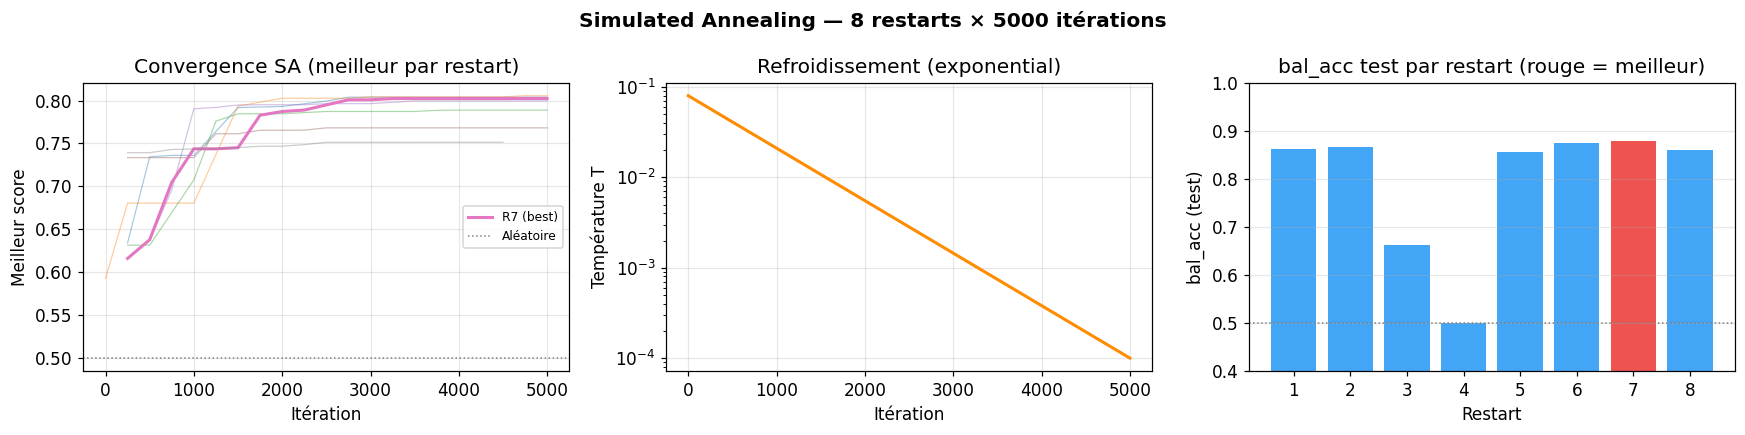

Meilleur restart : val_acc=0.8781  pire=0.5000  moy=0.7949


In [196]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle(f'Simulated Annealing — {N_RESTARTS} restarts × {N_ITER_SA} itérations', fontweight='bold')

# Score de chaque restart
ax = axes[0]
for r, res in enumerate(all_results):
    h = res['history']
    iters = [x['iter'] for x in h]
    scores = [x['score'] for x in h]
    best_scores = [x['best_score'] for x in h]
    is_best = (res is best_result)
    ax.plot(iters, best_scores, lw=2 if is_best else 0.8,
            alpha=1.0 if is_best else 0.4,
            label=f'R{r+1} (best)' if is_best else None)
ax.axhline(0.5, color='gray', ls=':', lw=1, label='Aléatoire')
ax.set_xlabel('Itération'); ax.set_ylabel('Meilleur score')
ax.set_title('Convergence SA (meilleur par restart)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# Température
ax = axes[1]
if COOLING == 'exponential':
    temps_plot = TEMP_START * (TEMP_END/TEMP_START)**(np.linspace(0,1,200))
else:
    temps_plot = np.linspace(TEMP_START, TEMP_END, 200)
ax.semilogy(np.linspace(0, N_ITER_SA, 200), temps_plot, color='darkorange', lw=2)
ax.set_xlabel('Itération'); ax.set_ylabel('Température T')
ax.set_title(f'Refroidissement ({COOLING})')
ax.grid(True, alpha=0.3)

# Comparaison va_bal_acc par restart
ax = axes[2]
va_accs = [r['va_bal_acc'] for r in all_results]
colors = ['#42A5F5' if r is not best_result else '#EF5350' for r in all_results]
bars = ax.bar(range(1, N_RESTARTS+1), va_accs, color=colors)
ax.axhline(0.5, color='gray', ls=':', lw=1)
ax.set_xlabel('Restart'); ax.set_ylabel('bal_acc (test)')
ax.set_title('bal_acc test par restart (rouge = meilleur)')
ax.set_ylim(0.4, 1.0); ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout(); plt.show()

print(f'Meilleur restart : val_acc={max(va_accs):.4f}  pire={min(va_accs):.4f}  moy={np.mean(va_accs):.4f}')

## 10. Distribution Fout + carte de décision

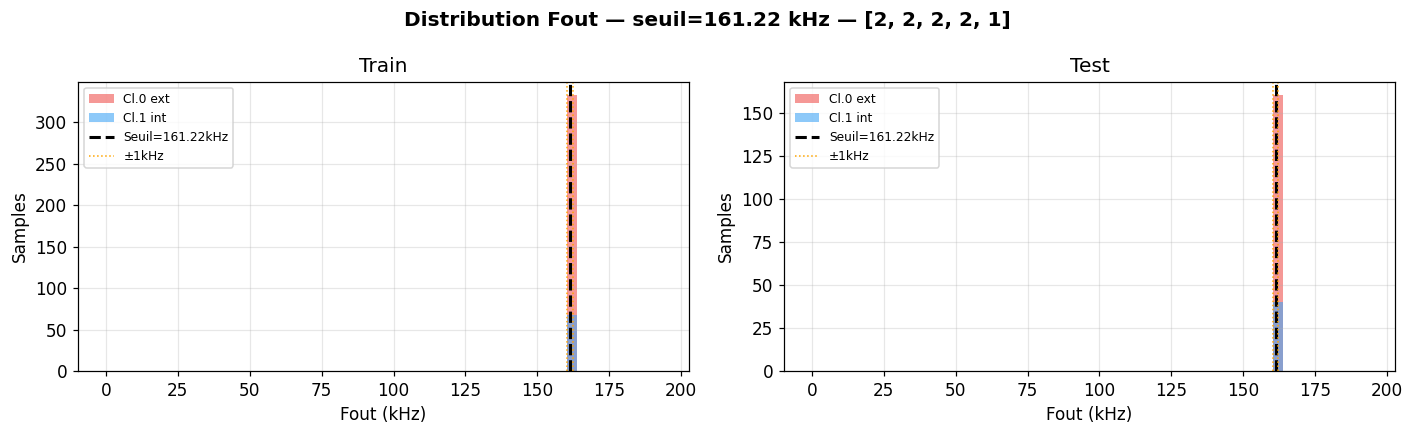

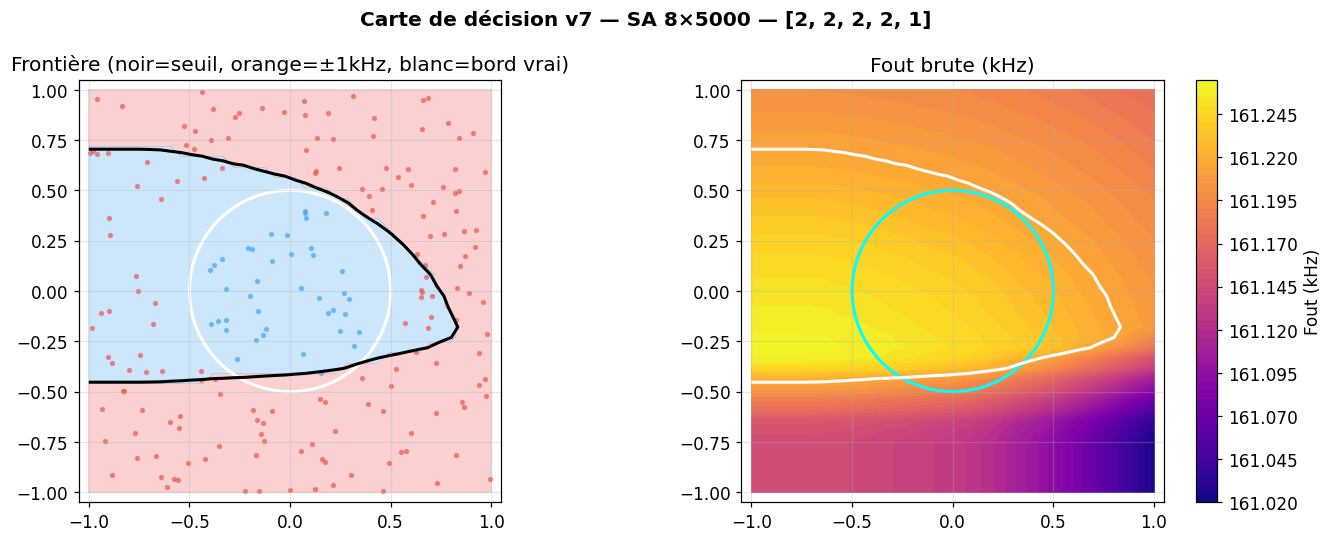

bal_acc test = 0.8781  |  acc cl0=0.7812  acc cl1=0.9750


In [197]:
# Distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle(f'Distribution Fout — seuil={best_thr*1e-3:.2f} kHz — {LAYER_SIZES}', fontweight='bold')
for ax, Fout, y, title in [(axes[0], Fout_tr, y_train, 'Train'), (axes[1], Fout_va, y_test, 'Test')]:
    bins = np.linspace(0, _F_MAX, 60)
    ax.hist(Fout[y==0]*1e-3, bins=bins*1e-3, alpha=0.6, color='#EF5350', label='Cl.0 ext')
    ax.hist(Fout[y==1]*1e-3, bins=bins*1e-3, alpha=0.6, color='#42A5F5', label='Cl.1 int')
    ax.axvline(best_thr*1e-3, color='k', lw=2, ls='--', label=f'Seuil={best_thr*1e-3:.2f}kHz')
    ax.axvline((best_thr-MIN_MARGIN_HZ)*1e-3, color='orange', lw=1, ls=':')
    ax.axvline((best_thr+MIN_MARGIN_HZ)*1e-3, color='orange', lw=1, ls=':', label='±1kHz')
    ax.set_xlabel('Fout (kHz)'); ax.set_ylabel('Samples'); ax.set_title(title)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# Carte de décision
res = 40
xs = np.linspace(-1, 1, res); ys = np.linspace(-1, 1, res)
XX, YY = np.meshgrid(xs, ys)
grid_V = np.ascontiguousarray(xy_to_voltage(np.column_stack([XX.ravel(), YY.ravel()])), dtype=np.float64)
Fout_g, _ = network_forward(grid_V, signs, widths)
pred_g  = (Fout_g >= best_thr).astype(int).reshape(XX.shape)
delta_g = (Fout_g.reshape(XX.shape) - best_thr) * 1e-3

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(f'Carte de décision v7 — SA {N_RESTARTS}×{N_ITER_SA} — {LAYER_SIZES}', fontweight='bold')

ax = axes[0]
ax.contourf(XX, YY, pred_g, levels=[-0.5,0.5,1.5], colors=['#EF535044','#42A5F544'])
ax.contour(XX, YY, delta_g, levels=[0], colors='k', linewidths=2)
ax.contour(XX, YY, delta_g, levels=[-1,1], colors='orange', linewidths=1, linestyles='--')
ax.add_patch(plt.Circle((0,0), DISK_RADIUS, color='white', fill=False, lw=2))
ax.scatter(X_test[y_test==0,0], X_test[y_test==0,1], s=6, c='#EF5350', alpha=0.6)
ax.scatter(X_test[y_test==1,0], X_test[y_test==1,1], s=6, c='#42A5F5', alpha=0.6)
ax.set_title('Frontière (noir=seuil, orange=±1kHz, blanc=bord vrai)')
ax.set_aspect('equal'); ax.set_xlim(-1.05,1.05); ax.set_ylim(-1.05,1.05)
ax.grid(True, alpha=0.3)

ax = axes[1]
cf = ax.contourf(XX, YY, Fout_g.reshape(XX.shape)*1e-3, levels=50, cmap='plasma')
plt.colorbar(cf, ax=ax, label='Fout (kHz)')
ax.contour(XX, YY, delta_g, levels=[0], colors='white', linewidths=2)
ax.contour(XX, YY, delta_g, levels=[-1,1], colors='orange', linewidths=1.5, linestyles='--')
ax.add_patch(plt.Circle((0,0), DISK_RADIUS, color='cyan', fill=False, lw=2))
ax.set_title('Fout brute (kHz)')
ax.set_aspect('equal'); ax.set_xlim(-1.05,1.05); ax.set_ylim(-1.05,1.05)
ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
print(f'bal_acc test = {m_va["bal_acc"]:.4f}  |  acc cl0={m_va["acc0"]:.4f}  acc cl1={m_va["acc1"]:.4f}')

## 11. Diagnostic Itot

In [198]:
print('='*60)
print(f'  DIAGNOSTIC — Itot par couche (train complet)')
print(f'  Contrainte v7 : Itot >= {MIN_ITOT_A*1e12:.0f} pA')
print('='*60)

F = _input_f_batch(V_train_f64, _INPUT_V_AXIS, _INPUT_F_AXIS)
all_ok = True
for li, (sm, wm) in enumerate(zip(signs, widths)):
    F, Itot = layer_forward_batch(F, sm, wm)
    itots = Itot.ravel()
    pct_neg = 100*np.mean(itots < MIN_ITOT_A)
    pct_silent = 100*np.mean((itots >= 0) & (itots < NEURON_I_AXIS[0]))
    pct_sat = 100*np.mean(itots > NEURON_I_AXIS[-1])
    ok = '✓' if pct_neg == 0 else f'✗ {pct_neg:.1f}% hors borne'
    if pct_neg > 0: all_ok = False
    print(f'  Couche {li}: [{itots.min()*1e12:.1f}, {itots.max()*1e12:.1f}] pA  {ok}')
    print(f'           silencieux={pct_silent:.1f}%  saturés={pct_sat:.1f}%')
print('='*60)
print('  ✓ OK' if all_ok else '  ✗ VIOLATION — augmenter MIN_ITOT_PENALTY')
print('='*60)

  DIAGNOSTIC — Itot par couche (train complet)
  Contrainte v7 : Itot >= -6 pA
  Couche 0: [190.0, 678.6] pA  ✓
           silencieux=0.0%  saturés=0.0%
  Couche 1: [353.9, 1020.0] pA  ✓
           silencieux=0.0%  saturés=2.8%
  Couche 2: [481.2, 755.1] pA  ✓
           silencieux=0.0%  saturés=0.0%
  Couche 3: [571.9, 573.9] pA  ✓
           silencieux=0.0%  saturés=0.0%
  ✓ OK


## 12. Export poids Cadence

In [199]:
layer_names = (['In->H1']
               + [f'H{k}->H{k+1}' for k in range(1, len(signs)-1)]
               + [f'H{len(signs)-1}->Out'])

print(f'\n=== POIDS FINAUX {LAYER_SIZES} — seuil={best_thr*1e-3:.3f} kHz ===')
for k, (s, w, ln) in enumerate(zip(signs, widths, layer_names)):
    si = s.astype(int)
    print(f'\n  Couche {k+1} [{ln}]  {si.shape[0]}->{si.shape[1]}')
    print(f'    Signes :\n{si}')
    print(f'    Largeurs (um) :\n{w}')
    print(f'    EXC={int((si==1).sum())}  INH={int((si==-1).sum())}')

rows = []
for li, (s, w) in enumerate(zip(signs, widths)):
    si = s.astype(int)
    for i in range(si.shape[0]):
        for j in range(si.shape[1]):
            rows.append({'layer': li+1, 'pre': i, 'post': j,
                         'sign': int(si[i,j]), 'width_um': float(w[i,j]),
                         'type': 'EXC' if si[i,j]==1 else 'INH'})

df_w = pd.DataFrame(rows)
df_w.to_csv('weights_cadence_disk_v7.csv', index=False)

df_t = pd.DataFrame([{'threshold_Hz': best_thr, 'threshold_kHz': best_thr*1e-3,
                       'bal_acc_train': m_tr['bal_acc'], 'bal_acc_test': m_va['bal_acc'],
                       'acc0_test': m_va['acc0'], 'acc1_test': m_va['acc1']}])
df_t.to_csv('threshold_cadence_disk_v7.csv', index=False)

print('\nweights_cadence_disk_v7.csv :')
print(df_w.to_string(index=False))
print(f'\nthreshold_cadence_disk_v7.csv : {best_thr*1e-3:.3f} kHz')
print(f'bal_acc train={m_tr["bal_acc"]:.4f}  test={m_va["bal_acc"]:.4f}')


=== POIDS FINAUX [2, 2, 2, 2, 1] — seuil=161.215 kHz ===

  Couche 1 [In->H1]  2->2
    Signes :
[[ 1 -1]
 [ 1  1]]
    Largeurs (um) :
[[1.341  0.4082]
 [2.095  2.397 ]]
    EXC=3  INH=1

  Couche 2 [H1->H2]  2->2
    Signes :
[[ 1 -1]
 [-1  1]]
    Largeurs (um) :
[[1.04   0.6358]
 [0.6358 3.    ]]
    EXC=2  INH=2

  Couche 3 [H2->H3]  2->2
    Signes :
[[ 1 -1]
 [-1  1]]
    Largeurs (um) :
[[1.492  0.2261]
 [0.4992 1.944 ]]
    EXC=2  INH=2

  Couche 4 [H3->Out]  2->1
    Signes :
[[-1]
 [ 1]]
    Largeurs (um) :
[[0.8179]
 [1.341 ]]
    EXC=1  INH=1

weights_cadence_disk_v7.csv :
 layer  pre  post  sign  width_um type
     1    0     0     1    1.3410  EXC
     1    0     1    -1    0.4082  INH
     1    1     0     1    2.0950  EXC
     1    1     1     1    2.3970  EXC
     2    0     0     1    1.0400  EXC
     2    0     1    -1    0.6358  INH
     2    1     0    -1    0.6358  INH
     2    1     1     1    3.0000  EXC
     3    0     0     1    1.4920  EXC
     3    0     

## Annexe — Réglage du SA

| Paramètre | Valeur | Effet si on augmente |
|---|---|---|
| `N_ITER_SA` | 5000 | Meilleure qualité, plus long |
| `N_RESTARTS` | 8 | Plus de diversité, plus long |
| `TEMP_START` | 0.08 | Plus d'exploration initiale |
| `TEMP_END` | 1e-4 | Convergence plus serrée |
| `HIDDEN_SIZES` | [8,4] | Plus expressif → `[12,6]` ou `[16,8]` |

**Si la frontière est encore en arc :** augmenter `TEMP_START` (plus d'exploration)  
**Si accuracy faible :** augmenter `N_ITER_SA` ou `HIDDEN_SIZES`  
**Si trop lent :** réduire `HIDDEN_SIZES` à `[6,3]` ou `N_ITER_SA` à 2000